/var/folders/x2/qcdv4dps62x3jn5hrz_hdsq00000gn/T/ipykernel_60775/2036700563.py:42: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top10_genres.values, y=top10_genres.index, palette='Reds_r', ax=axes[1, 0])


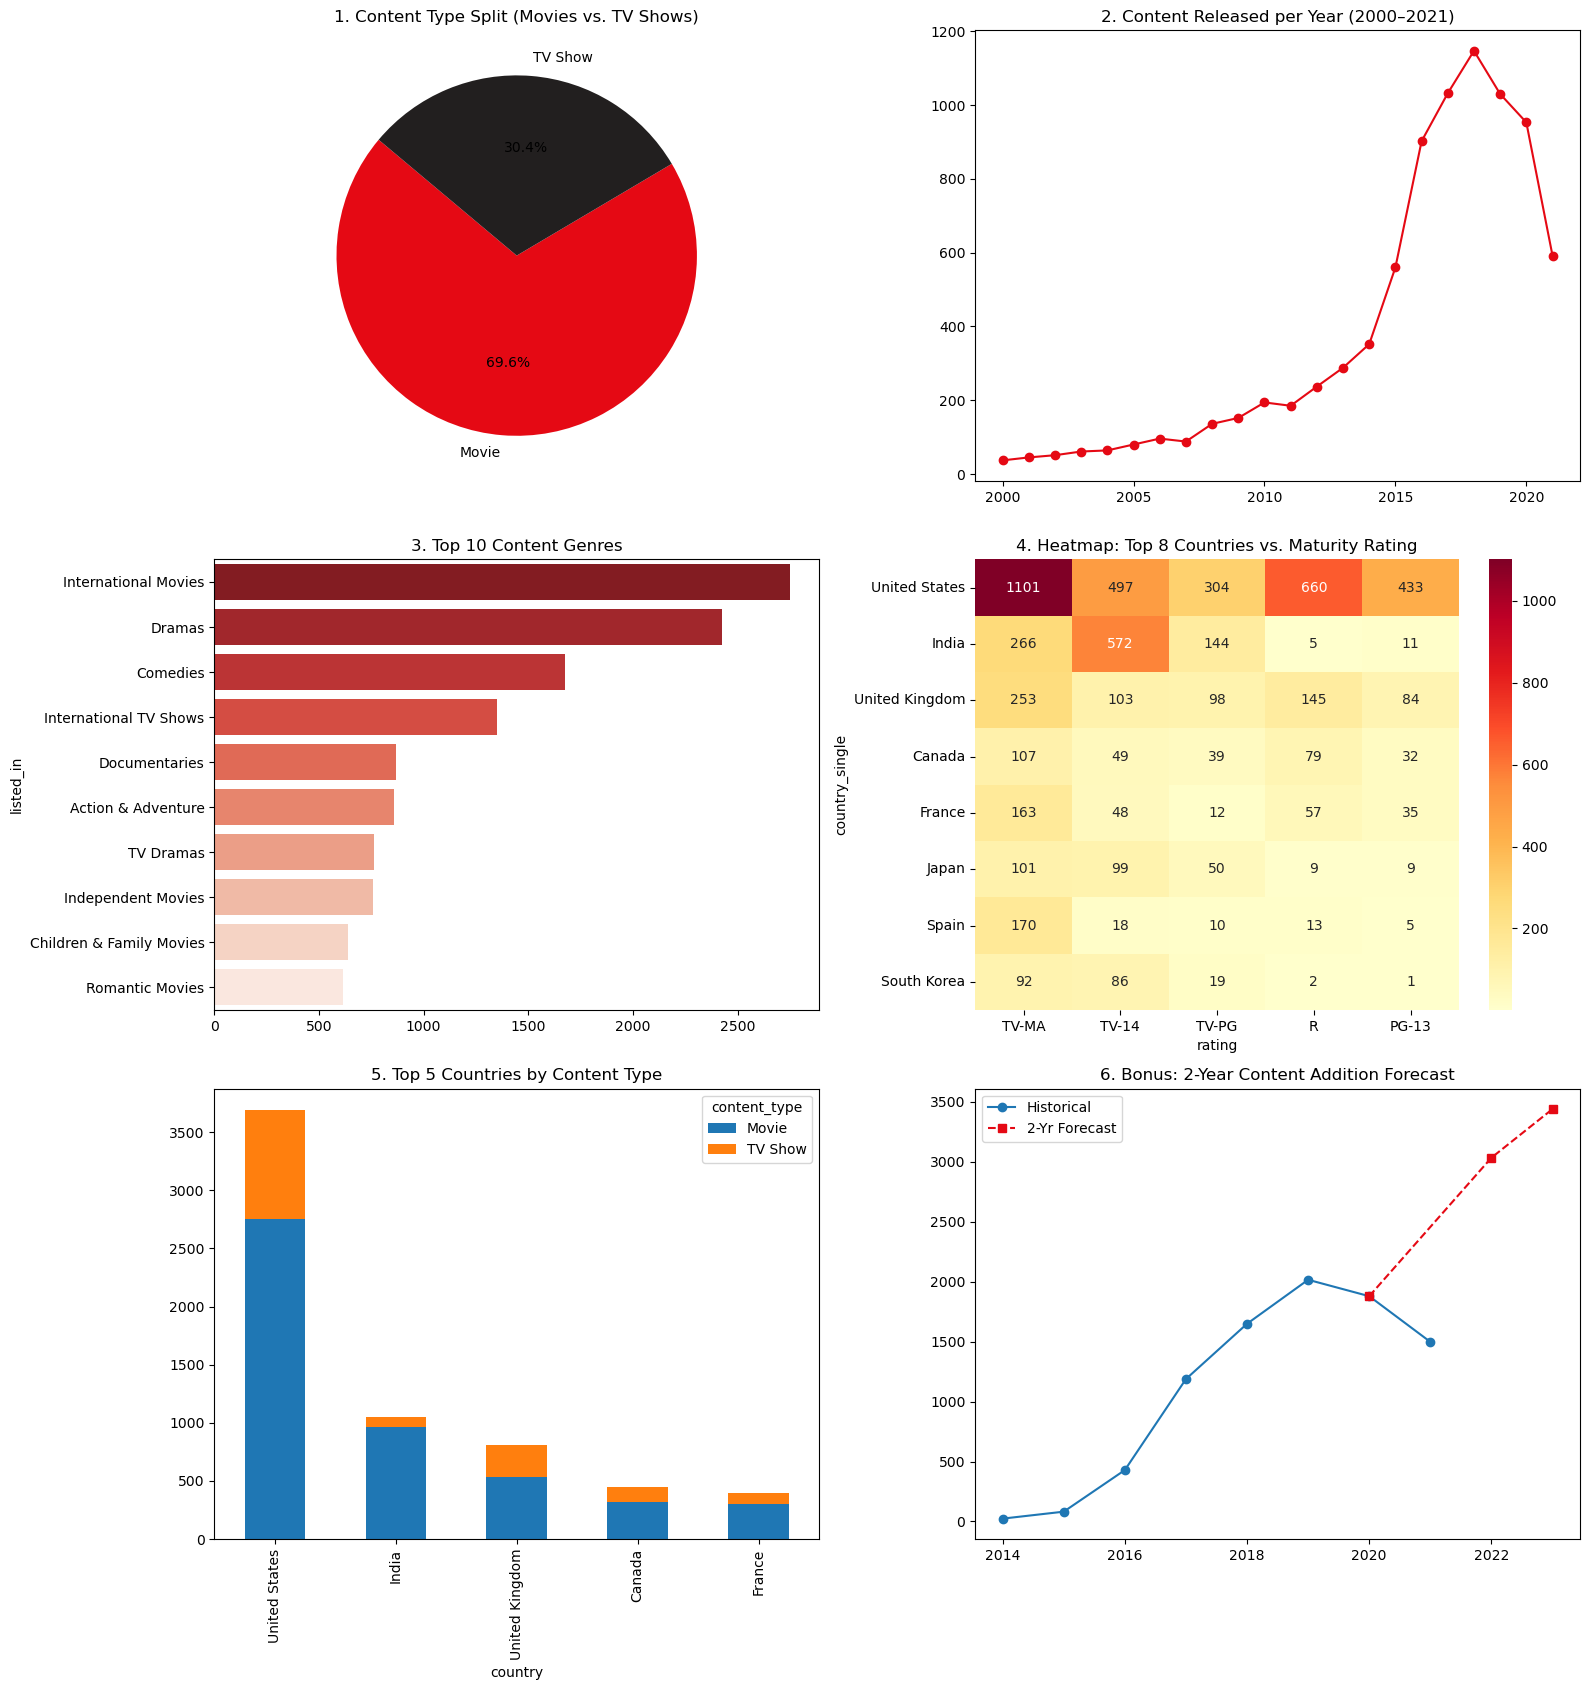

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression

# 1. Data Understanding & Cleaning
df_nf = pd.read_csv('netflix_titles.csv')
df_nf['date_added'] = pd.to_datetime(df_nf['date_added'].str.strip(), errors='coerce')
df_nf['year_added'] = df_nf['date_added'].dt.year

df_nf['director'] = df_nf['director'].fillna('Unknown')
df_nf['cast'] = df_nf['cast'].fillna('Unknown')
df_nf['country'] = df_nf['country'].fillna('Unknown')
df_nf['rating'] = df_nf['rating'].fillna('Not Rated')

df_nf['release_decade'] = (df_nf['release_year'] // 10) * 10
df_nf['is_movie'] = (df_nf['type'] == 'Movie').astype(int)

# 2. Feature Engineering
df_nf['content_type'] = df_nf['type']
countries_series = df_nf[df_nf['country'] != 'Unknown']['country'].str.split(',').explode().str.strip()
top5_countries = countries_series.value_counts().head(5)

genres_series = df_nf['listed_in'].str.split(',').explode().str.strip()
top10_genres = genres_series.value_counts().head(10)

# 3. Visualization & Bonus 2-Year Trend Prediction
fig, axes = plt.subplots(3, 2, figsize=(16, 17))

# Visual 1: Pie Chart (Movie vs TV Show)
type_counts = df_nf['content_type'].value_counts()
axes[0, 0].pie(type_counts.values, labels=type_counts.index, autopct='%1.1f%%', startangle=140, colors=['#e50914', '#221f1f'])
axes[0, 0].set_title('1. Content Type Split (Movies vs. TV Shows)')

# Visual 2: Line Plot (Content Released per Year)
rel_recent = df_nf[df_nf['release_year'] >= 2000]['release_year'].value_counts().sort_index()
axes[0, 1].plot(rel_recent.index, rel_recent.values, marker='o', color='#e50914')
axes[0, 1].set_title('2. Content Released per Year (2000–2021)')

# Visual 3: Barplot (Top 10 Genres)
sns.barplot(x=top10_genres.values, y=top10_genres.index, palette='Reds_r', ax=axes[1, 0])
axes[1, 0].set_title('3. Top 10 Content Genres')

# Visual 4: Heatmap (Top 8 Countries vs Maturity Rating)
df_exp = df_nf[df_nf['country'] != 'Unknown'].assign(country_single=df_nf['country'].str.split(',')).explode('country_single')
df_exp['country_single'] = df_exp['country_single'].str.strip()
top8_c = df_exp['country_single'].value_counts().head(8).index
top5_r = ['TV-MA', 'TV-14', 'TV-PG', 'R', 'PG-13']
sub_c = df_exp[df_exp['country_single'].isin(top8_c)]
ct_heatmap = pd.crosstab(sub_c['country_single'], sub_c['rating'])[top5_r].loc[top8_c]
sns.heatmap(ct_heatmap, annot=True, fmt='d', cmap='YlOrRd', ax=axes[1, 1])
axes[1, 1].set_title('4. Heatmap: Top 8 Countries vs. Maturity Rating')

# Visual 5: Top 5 Countries by Content Type
sub_c5 = df_exp[df_exp['country_single'].isin(top5_countries.index)]
pd.crosstab(sub_c5['country_single'], sub_c5['content_type']).loc[top5_countries.index].plot(kind='bar', stacked=True, ax=axes[2, 0])
axes[2, 0].set_title('5. Top 5 Countries by Content Type')

# Visual 6: Bonus 2-Year Forecast
added_per_year = df_nf['year_added'].dropna().astype(int).value_counts().sort_index()
full_years = added_per_year.loc[2015:2020]
lr = LinearRegression().fit(full_years.index.values.reshape(-1, 1), full_years.values)
preds = lr.predict(np.array([[2022], [2023]]))
axes[2, 1].plot(added_per_year.loc[2014:2021].index, added_per_year.loc[2014:2021].values, marker='o', label='Historical')
axes[2, 1].plot([2020, 2022, 2023], [full_years.loc[2020], preds[0], preds[1]], marker='s', linestyle='--', color='#e50914', label='2-Yr Forecast')
axes[2, 1].set_title('6. Bonus: 2-Year Content Addition Forecast')
axes[2, 1].legend()

plt.tight_layout()
plt.savefig('task4_netflix_eda.png', dpi=200)
plt.show()